#APM1220 – Applied Multivariate Data Analysis
#Summative Assessment 1

### Multivariate Analysis of the Wine Quality Dataset

## Part A – Data Preparation and Exploratory Analysis


Dataset Structure:
 fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
ph                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                    object
dtype: object

Total Observations: 6497, Variables: 13

Missing Values per Variable:
 fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
color                   0
dtype: int64

Duplicate Observations: 1177

Descriptive Statistics:
        fixed_acidity  volatile_acidity  citric_acid  residual_sugar  \


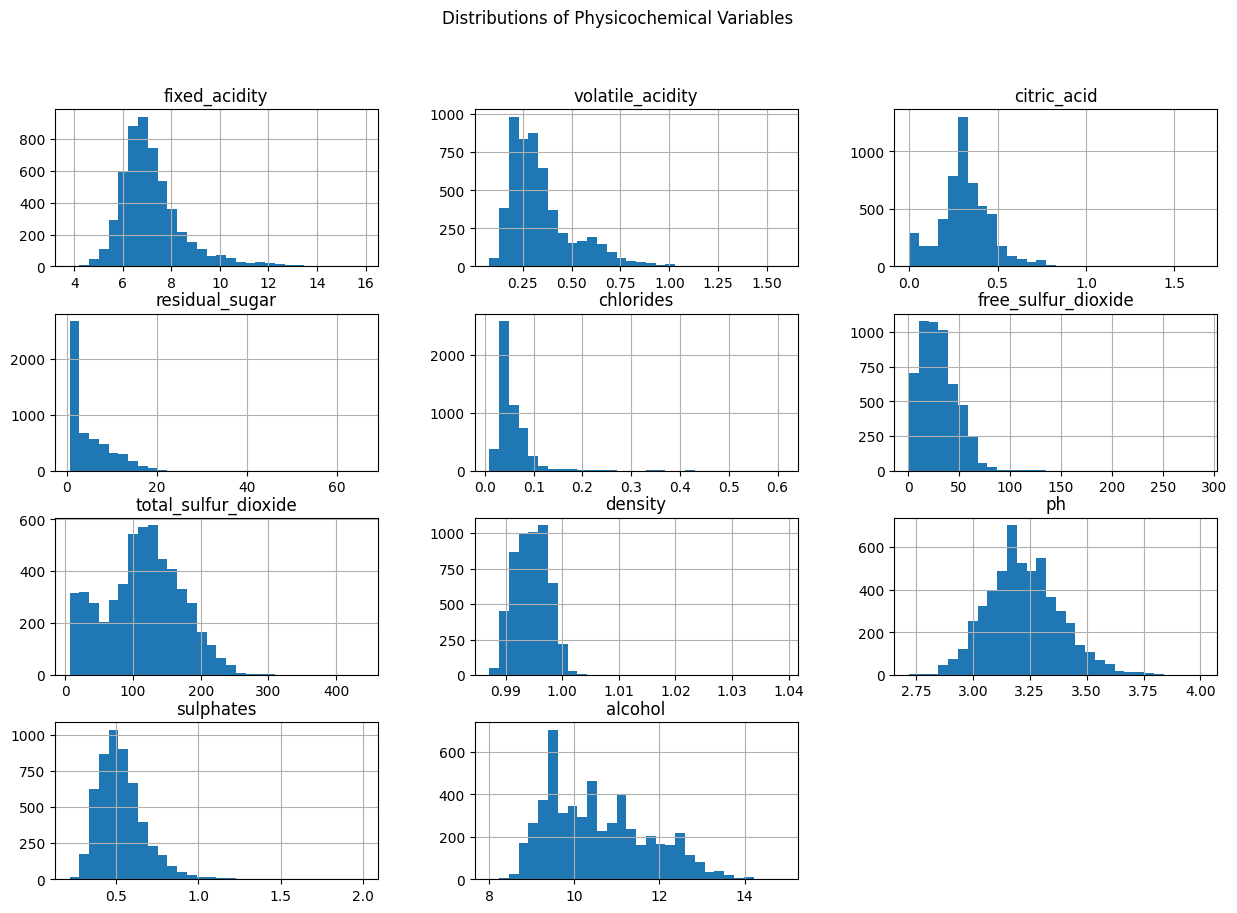

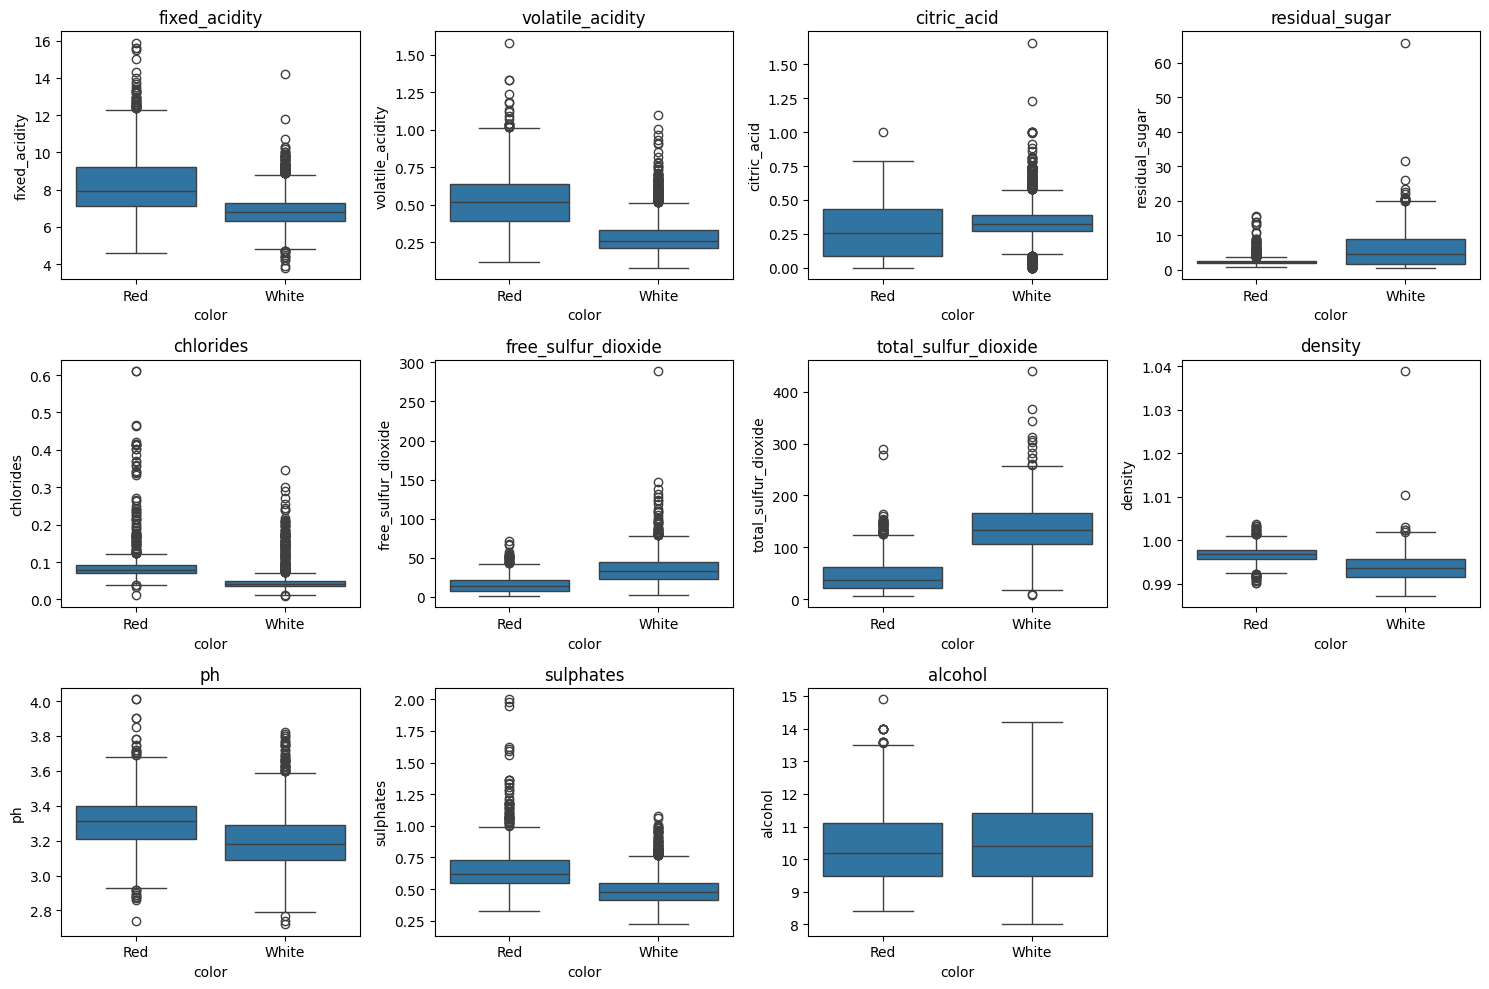

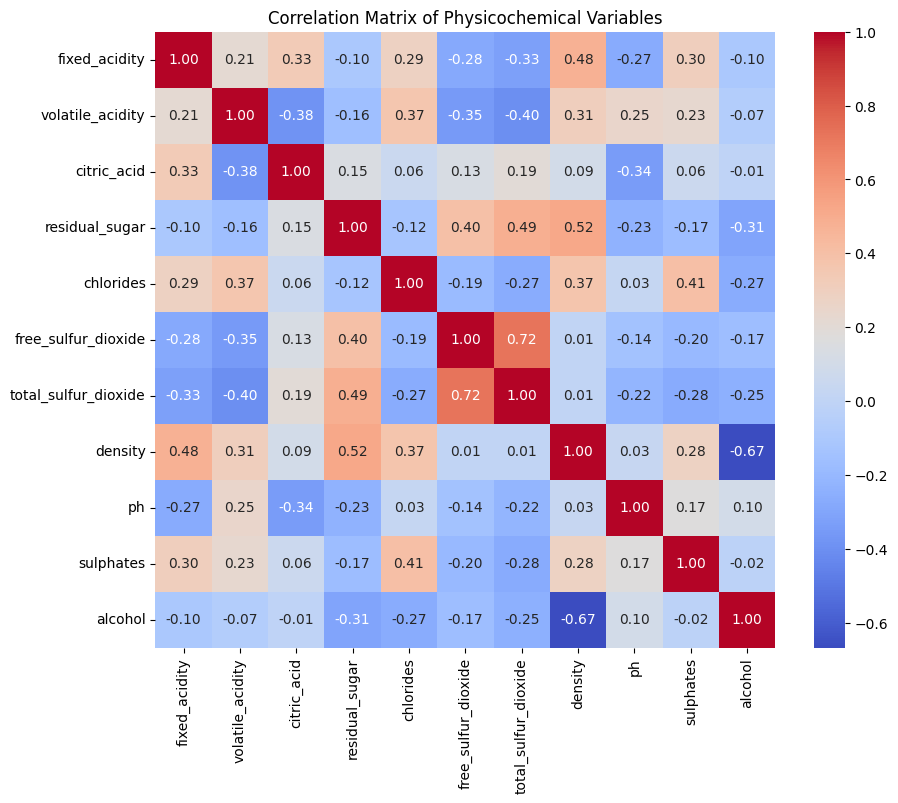

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1-3. Import datasets, create color variable, and combine
red = pd.read_csv('/content/winequality-red.csv', sep=';')
white = pd.read_csv('/content/winequality-white.csv', sep=';')

red['color'] = 'Red'
white['color'] = 'White'
wine = pd.concat([red, white], ignore_index=True)

# Clean column names
wine.columns = wine.columns.str.replace(' ', '_').str.lower()

# 4-7. Examine structure, missing values, and duplicates
print("Dataset Structure:\n", wine.dtypes)
print(f"\nTotal Observations: {wine.shape[0]}, Variables: {wine.shape[1]}")
print("\nMissing Values per Variable:\n", wine.isnull().sum())
print("\nDuplicate Observations:", wine.duplicated().sum())

# Drop duplicates
wine_clean = wine.drop_duplicates().copy()

# Isolate quantitative variables (excluding color and quality)
quant_vars = wine_clean.drop(columns=['color', 'quality'])

# 9. Descriptive statistics
print("\nDescriptive Statistics:\n", quant_vars.describe())

# 10. Examine distributions (Histograms)
quant_vars.hist(bins=30, figsize=(15, 10))
plt.suptitle('Distributions of Physicochemical Variables')
plt.show()

# 8 & 12. Visualizations comparing red and white wines (Boxplots)
plt.figure(figsize=(15, 10))
for i, col in enumerate(quant_vars.columns, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(x='color', y=col, data=wine_clean)
    plt.title(col)
plt.tight_layout()
plt.show()

# 11. Correlation matrix heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(quant_vars.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Physicochemical Variables')
plt.show()

## Part B – Multivariate Analysis of Variance (MANOVA)

In [ ]:
import statsmodels.api as sm
from statsmodels.multivariate.manova import MANOVA
from scipy import stats
from scipy.stats import shapiro, chi2
from scipy.spatial import distance

# 1. State Hypotheses
# H0: The mean vectors of the selected variables are the same for red and white wines.
# H1: The mean vectors differ between red and white wines.

# Selected dependent variables based on EDA differences
selected_vars = ['volatile_acidity', 'chlorides', 'fixed_acidity', 'sulphates']
df_manova = wine_clean[selected_vars]

# 2a. Assess Assumptions: Homogeneity of Variance (Levene's Test)
print("Levene's Test for Homogeneity of Variance:")
for var in selected_vars:
    stat, p = stats.levene(wine_clean[wine_clean['color'] == 'Red'][var],
                           wine_clean[wine_clean['color'] == 'White'][var])
    print(f"{var}: Statistic={stat:.4f}, p-value={p:.4f}")

# 2b. Assess Assumptions: Multivariate Normality (Shapiro-Wilk)
print("\nShapiro-Wilk Test for Normality (Sample of 500):")
sample = wine_clean.sample(500, random_state=42)
for var in selected_vars:
    stat, p = shapiro(sample[var])
    print(f"{var}: Statistic={stat:.4f}, p-value={p:.4f}")

# 2c. Assess Assumptions: Multivariate Outliers (Mahalanobis Distance)
cov_matrix = np.cov(df_manova.values, rowvar=False)
inv_cov_matrix = np.linalg.inv(cov_matrix)
mean_distr = df_manova.mean(axis=0).values

m_dist_sq = [distance.mahalanobis(row, mean_distr, inv_cov_matrix) ** 2 for row in df_manova.values]

# Calculate p-values
p_vals = 1 - chi2.cdf(m_dist_sq, len(selected_vars))
outliers = sum(p_vals < 0.001)
print(f"\nPotential Multivariate Outliers detected (p < 0.001): {outliers}")

# 3. Conduct the MANOVA
formula = 'volatile_acidity + chlorides + fixed_acidity + sulphates ~ color'
manova = MANOVA.from_formula(formula, data=wine_clean)
print("\nMANOVA Results:")
print(manova.mv_test())

# 4. Follow-up analyses (Univariate ANOVAs)
print("\nFollow-up Univariate ANOVAs:")
for var in selected_vars:
    model = sm.OLS.from_formula(f'{var} ~ color', data=wine_clean).fit()
    anova_table = sm.stats.anova_lm(model, typ=2)
    print(f"\nANOVA for {var}:\n", anova_table)

Levene's Test for Homogeneity of Variance:
volatile_acidity: Statistic=703.7038, p-value=0.0000
chlorides: Statistic=103.5126, p-value=0.0000
fixed_acidity: Statistic=732.1647, p-value=0.0000
sulphates: Statistic=93.2114, p-value=0.0000

Shapiro-Wilk Test for Normality (Sample of 500):
volatile_acidity: Statistic=0.8806, p-value=0.0000
chlorides: Statistic=0.5894, p-value=0.0000
fixed_acidity: Statistic=0.9157, p-value=0.0000
sulphates: Statistic=0.8220, p-value=0.0000

Potential Multivariate Outliers detected (p < 0.001): 145

MANOVA Results:
                    Multivariate linear model
                                                                  
------------------------------------------------------------------
       Intercept         Value  Num DF   Den DF   F Value   Pr > F
------------------------------------------------------------------
          Wilks' lambda  0.0355 4.0000 5315.0000 36086.7001 0.0000
         Pillai's trace  0.9645 4.0000 5315.0000 36086.7001 0.0000
 H

## Part C – Principal Component Analysis (PCA)

PCA Summary:
     Component  Eigenvalue  Variance_Explained  Cumulative_Variance
0           1    2.988937            0.271671             0.271671
1           2    2.475732            0.225024             0.496695
2           3    1.587581            0.144298             0.640993
3           4    0.953581            0.086673             0.727666
4           5    0.742375            0.067476             0.795142
5           6    0.627156            0.057003             0.852145
6           7    0.521138            0.047367             0.899513
7           8    0.507694            0.046145             0.945658
8           9    0.336784            0.030611             0.976269
9          10    0.226001            0.020542             0.996811
10         11    0.035089            0.003189             1.000000


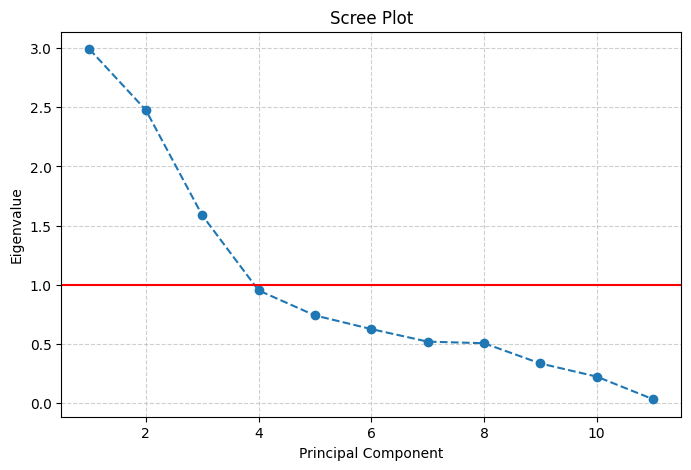


Component Loadings:
                            PC1       PC2       PC3
fixed_acidity        -0.274858  0.306633  0.423753
volatile_acidity     -0.389696  0.069524 -0.311884
citric_acid           0.134030  0.219389  0.577169
residual_sugar        0.297557  0.368023 -0.172807
chlorides            -0.319565  0.274872 -0.008704
free_sulfur_dioxide   0.425781  0.141162 -0.138410
total_sulfur_dioxide  0.476251  0.162208 -0.115753
density              -0.136573  0.565079 -0.184412
ph                   -0.187894 -0.187346 -0.464527
sulphates            -0.317580  0.157844  0.074000
alcohol              -0.032342 -0.465241  0.268838


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Variables for PCA
features = ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
            'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
            'ph', 'sulphates', 'alcohol']
X = wine_clean[features]

# 2. Standardize the variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3 & 4. Run PCA, calculate Eigenvalues, and Variance Explained
pca = PCA()
pca.fit(X_scaled)

eigenvalues = pca.explained_variance_
variance_explained = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_explained)

pca_summary = pd.DataFrame({
    'Component': range(1, len(eigenvalues) + 1),
    'Eigenvalue': eigenvalues,
    'Variance_Explained': variance_explained,
    'Cumulative_Variance': cumulative_variance
})
print("PCA Summary:\n", pca_summary)

# 5. Visualize the PCA (Scree Plot)
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(eigenvalues) + 1), eigenvalues, marker='o', linestyle='--')
plt.axhline(y=1, color='r', linestyle='-')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Eigenvalue')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 6. Component Loadings (Retaining 3 components based on Eigenvalue > 1 rule and Scree plot)
pca_retained = PCA(n_components=3)
pca_retained.fit(X_scaled)
loadings = pd.DataFrame(pca_retained.components_.T, columns=['PC1', 'PC2', 'PC3'], index=features)
print("\nComponent Loadings:\n", loadings)

## Part D – Exploratory Factor Analysis (EFA)

Bartlett's Test of Sphericity:
Chi-Square: 29789.8901, p-value: 0.0000e+00

Kaiser-Meyer-Olkin (KMO) Measure: 0.4013

EFA Eigenvalues:
 [2.98837552 2.47526679 1.5872824  0.95340157 0.74223529 0.62703796
 0.52103998 0.50759857 0.33672096 0.22595817 0.03508278]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


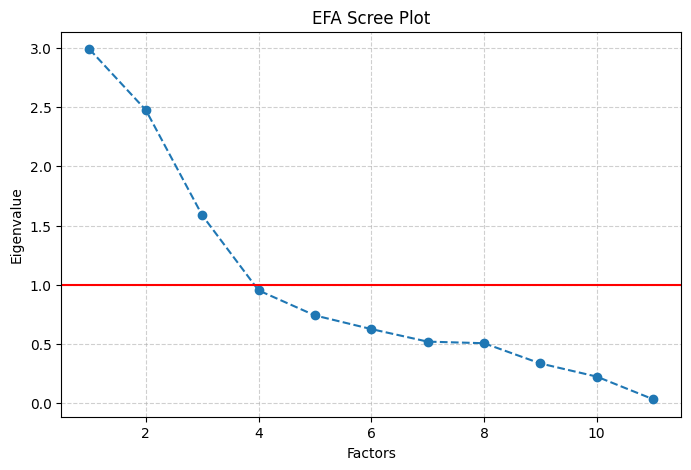


Factor Loadings (Promax Rotation):
                       Factor 1  Factor 2  Factor 3
fixed_acidity         0.762097  0.053212  0.556443
volatile_acidity      0.535268  0.176175 -0.497179
citric_acid           0.128867 -0.037565  0.858764
residual_sugar       -0.312551  0.704339  0.071861
chlorides             0.655962  0.278462 -0.004433
free_sulfur_dioxide  -0.632522  0.414471  0.057445
total_sulfur_dioxide -0.690767  0.443952  0.114055
density               0.475753  0.843498 -0.015610
ph                    0.014886 -0.009334 -0.726493
sulphates             0.614677  0.066517  0.043302
alcohol              -0.123149 -0.816008  0.101151

Communalities:
                       Communality
fixed_acidity            0.893251
volatile_acidity         0.564736
citric_acid              0.755493
residual_sugar           0.598946
chlorides                0.507848
free_sulfur_dioxide      0.575171
total_sulfur_dioxide     0.687261
density                  0.938074
ph                       0.5

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [ ]:
from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

# 1. Assess factorability
chi_square_value, p_value = calculate_bartlett_sphericity(X_scaled)
kmo_all, kmo_model = calculate_kmo(X_scaled)

print("Bartlett's Test of Sphericity:")
print(f"Chi-Square: {chi_square_value:.4f}, p-value: {p_value:.4e}")
print(f"\nKaiser-Meyer-Olkin (KMO) Measure: {kmo_model:.4f}")

# 2. Determine the number of factors (Eigenvalues and Scree Plot)
fa_temp = FactorAnalyzer(n_factors=X_scaled.shape[1], rotation=None)
fa_temp.fit(X_scaled)
ev, v = fa_temp.get_eigenvalues()
print("\nEFA Eigenvalues:\n", ev)

plt.figure(figsize=(8, 5))
plt.plot(range(1, X_scaled.shape[1] + 1), ev, marker='o', linestyle='--')
plt.axhline(y=1, color='r', linestyle='-')
plt.title('EFA Scree Plot')
plt.xlabel('Factors')
plt.ylabel('Eigenvalue')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 3 & 4. Extraction Method: Principal Axis Factoring (method='principal')
# Rotation Method: Promax (oblique rotation chosen because chemical traits are naturally correlated)
n_factors = 3 # Chosen based on the Eigenvalues > 1 rule and the Scree plot elbow
fa = FactorAnalyzer(n_factors=n_factors, rotation='promax', method='principal')
fa.fit(X_scaled)

# 5. Examine factor loadings and communalities
factor_loadings = pd.DataFrame(fa.loadings_, index=features,
                               columns=[f'Factor {i+1}' for i in range(n_factors)])
communalities = pd.DataFrame(fa.get_communalities(), index=features, columns=['Communality'])

print("\nFactor Loadings (Promax Rotation):\n", factor_loadings)
print("\nCommunalities:\n", communalities)